In [26]:
!pip install tensorflow matplotlib seaborn
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt



In [4]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [5]:
!kaggle datasets list


ref                                                           title                                          size  lastUpdated          downloadCount  voteCount  usabilityRating  
------------------------------------------------------------  --------------------------------------------  -----  -------------------  -------------  ---------  ---------------  
bhadramohit/customer-shopping-latest-trends-dataset           Customer Shopping (Latest Trends) Dataset      76KB  2024-11-23 15:26:12          16996        334  1.0              
hopesb/student-depression-dataset                             Student Depression Dataset.                   454KB  2024-11-22 17:56:03          13575        185  1.0              
bushraqurban/tourism-and-economic-impact                      ✈️ Tourism and Economic Impact Dataset💰       270KB  2024-12-22 08:47:37            861         26  1.0              
mujtabamatin/air-quality-and-pollution-assessment             Air Quality and Pollution Assessment  

In [6]:
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset


Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
 99% 2.68G/2.70G [00:13<00:00, 234MB/s]
100% 2.70G/2.70G [00:13<00:00, 210MB/s]


In [7]:
!unzip new-plant-diseases-dataset.zip -d ./plant_diseases


Streaming output truncated to the last 5000 lines.
  inflating: ./plant_diseases/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid/Strawberry___healthy/273a7a9e-18be-4b6a-976a-fa5ffd69b731___RS_HL 4366_90deg.JPG  
  inflating: ./plant_diseases/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid/Strawberry___healthy/275f8963-f4f4-4903-962b-1da716725d08___RS_HL 4780_90deg.JPG  
  inflating: ./plant_diseases/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid/Strawberry___healthy/275f8963-f4f4-4903-962b-1da716725d08___RS_HL 4780_new30degFlipLR.JPG  
  inflating: ./plant_diseases/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid/Strawberry___healthy/27c2aaa4-de4b-4fb1-ba8d-14d4b24b2afa___RS_HL 4665.JPG  
  inflating: ./plant_diseases/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/valid/Strawberry___healthy/27c2aaa4-de4b-4fb1-ba8d-14d4b24b2

In [9]:
!ls ./plant_diseases


'new plant diseases dataset(augmented)'  'New Plant Diseases Dataset(Augmented)'   test


In [20]:
train_dir = "/content/plant_diseases/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"
valid_dir = "/content/plant_diseases/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid"


In [44]:
training_set = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    batch_size=32,
    image_size=(224, 224),
    shuffle=True
)

validation_set = tf.keras.utils.image_dataset_from_directory(
    valid_dir,
    labels="inferred",
    label_mode="categorical",
    batch_size=32,
    image_size=(224, 224),
    shuffle=True
)


Found 70295 files belonging to 38 classes.
Found 17572 files belonging to 38 classes.


In [29]:
cnn = tf.keras.models.Sequential()

In [47]:
from tensorflow.keras import layers, models

cnn = models.Sequential([
    layers.InputLayer(shape=[224, 224, 3]),  # Use 'shape' instead of 'input_shape'
    layers.Conv2D(filters=32, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),

    layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(filters=64, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),

    layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(filters=128, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),

    layers.Conv2D(filters=256, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(filters=256, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),

    layers.Conv2D(filters=512, kernel_size=3, padding='same', activation='relu'),
    layers.Conv2D(filters=512, kernel_size=3, activation='relu'),
    layers.MaxPool2D(pool_size=2, strides=2),

    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(units=1500, activation='relu'),
    layers.Dropout(0.4),

    # Output layer
    layers.Dense(units=38, activation='softmax')
])

# Compile the model
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [48]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy'])


In [49]:
cnn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_46 (Conv2D)                   │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_47 (Conv2D)                   │ (None, 222, 222, 32)        │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_21 (MaxPooling2D)      │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_48 (Conv2D)                   │ (None, 111, 111, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_49 (Conv2D)                   │ (None, 109, 109, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_22 (MaxPooling2D)      │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_50 (Conv2D)                   │ (None, 54, 54, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_51 (Conv2D)                   │ (None, 52, 52, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_23 (MaxPooling2D)      │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_52 (Conv2D)                   │ (None, 26, 26, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_53 (Conv2D)                   │ (None, 24, 24, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_24 (MaxPooling2D)      │ (None, 12, 12, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_54 (Conv2D)                   │ (None, 12, 12, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_55 (Conv2D)                   │ (None, 10, 10, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_25 (MaxPooling2D)      │ (None, 5, 5, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 5, 5, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 12800)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 1500)                │      19,201,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 1500)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 38)                  │          57,038 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,970,762 (91.44 MB)

 Trainable params: 23,970,762 (91.44 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
# Fit the model using the training and validation datasets
training_history = cnn.fit(
    x=training_set,            # Training dataset
    validation_data=validation_set,  # Validation dataset
    epochs=10,                 # Number of epochs to train the model
    batch_size=32,             # Specify batch size (optional, but can help with performance)
    verbose=1                  # Verbosity level: 1 shows progress bar, 0 is silent, 2 is per-epoch logs
)


Epoch 1/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 399s 171ms/step - accuracy: 0.4873 - loss: 1.8555 - val_accuracy: 0.8919 - val_loss: 0.3496
Epoch 2/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 419s 170ms/step - accuracy: 0.8765 - loss: 0.3841 - val_accuracy: 0.9368 - val_loss: 0.1929
Epoch 3/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 354s 161ms/step - accuracy: 0.9287 - loss: 0.2244 - val_accuracy: 0.9350 - val_loss: 0.1993
Epoch 4/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 381s 161ms/step - accuracy: 0.9519 - loss: 0.1465 - val_accuracy: 0.9623 - val_loss: 0.1126
Epoch 5/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 400s 169ms/step - accuracy: 0.9669 - loss: 0.0983 - val_accuracy: 0.9578 - val_loss: 0.1333
Epoch 6/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.9719 - loss: 0.0898Epoch 7/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 401s 169ms/step - accuracy: 0.9770 - loss: 0.0720 - val_accuracy: 0.9702 - val_loss: 0.0920
Epoch 8/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 352s 160ms/step - accuracy: 0.9808 - loss: 0.0596 - val_accuracy:

In [51]:
#Training set Accuracy
train_loss, train_acc = cnn.evaluate(training_set)
print('Training accuracy:', train_acc)


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 96s 44ms/step - accuracy: 0.9941 - loss: 0.0189
Training accuracy: 0.9947506785392761


In [52]:
#Validation set Accuracy
val_loss, val_acc = cnn.evaluate(validation_set)
print('Validation accuracy:', val_acc)

550/550 ━━━━━━━━━━━━━━━━━━━━ 23s 42ms/step - accuracy: 0.9732 - loss: 0.0965
Validation accuracy: 0.9726837873458862


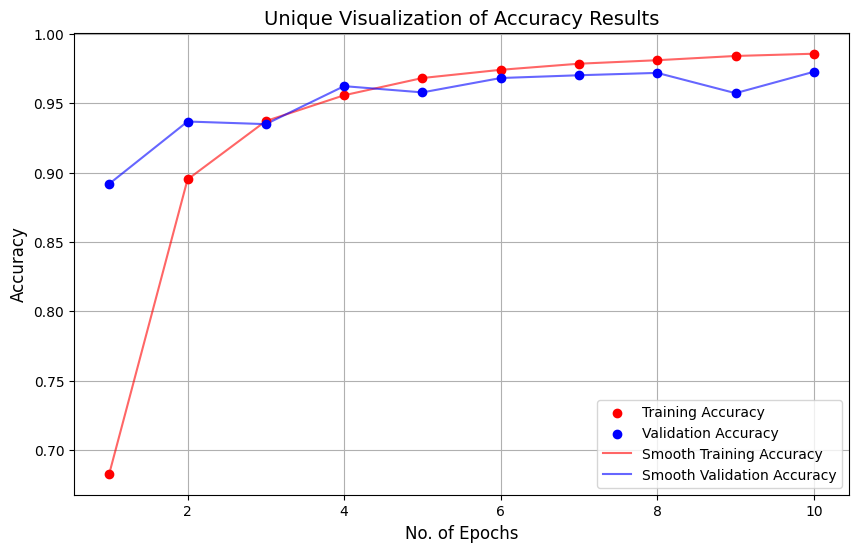

In [54]:
import matplotlib.pyplot as plt
import numpy as np

# Data for epochs and accuracy
epochs = [i for i in range(1, 11)]
train_accuracy = training_history.history['accuracy']
val_accuracy = training_history.history['val_accuracy']

# Scatter plot with a smooth line
plt.figure(figsize=(10,6))
plt.scatter(epochs, train_accuracy, color='red', label='Training Accuracy', zorder=5)
plt.scatter(epochs, val_accuracy, color='blue', label='Validation Accuracy', zorder=5)

# Smooth line fitting (using a simple interpolation)
x_vals = np.linspace(1, 10, 100)
train_line = np.interp(x_vals, epochs, train_accuracy)
val_line = np.interp(x_vals, epochs, val_accuracy)

plt.plot(x_vals, train_line, color='red', linestyle='-', alpha=0.6, label='Smooth Training Accuracy')
plt.plot(x_vals, val_line, color='blue', linestyle='-', alpha=0.6, label='Smooth Validation Accuracy')

# Adding labels, title, and legend
plt.xlabel('No. of Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Unique Visualization of Accuracy Results', fontsize=14)
plt.legend()
plt.grid(True)

# Show the plot
plt.show()


In [55]:
cnn.save('trained_plant_disease_model.keras')

In [56]:
training_history.history #Return Dictionary of history

{'accuracy': [0.6829504370689392,
  0.8950707912445068,
  0.9371647834777832,
  0.9557578563690186,
  0.9681912064552307,
  0.9741091132164001,
  0.9785048961639404,
  0.981022834777832,
  0.9840813875198364,
  0.9857031106948853],
 'loss': [1.083065152168274,
  0.32361477613449097,
  0.19573694467544556,
  0.13446418941020966,
  0.09477458149194717,
  0.08056943118572235,
  0.06594858318567276,
  0.0587017685174942,
  0.048190172761678696,
  0.044056687504053116],
 'val_accuracy': [0.891930341720581,
  0.9368312954902649,
  0.9349533319473267,
  0.9623264074325562,
  0.9578306674957275,
  0.9681880474090576,
  0.9701798558235168,
  0.9718871116638184,
  0.9572615623474121,
  0.9726837873458862],
 'val_loss': [0.34960952401161194,
  0.19289454817771912,
  0.19932961463928223,
  0.11262647807598114,
  0.13329683244228363,
  0.1126413345336914,
  0.09199872612953186,
  0.09657091647386551,
  0.14538909494876862,
  0.09836068004369736]}

In [57]:
#Recording History in json
import json
with open('training_hist.json','w') as f:
  json.dump(training_history.history,f)

In [58]:
print(training_history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


TESTING THE MODEL

In [61]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import matplotlib.pyplot as plt

In [64]:
import tensorflow as tf

# Load the validation dataset
validation_set = tf.keras.utils.image_dataset_from_directory(
    '/content/plant_diseases/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid',                            # Directory for validation images
    labels="inferred",                   # Labels are inferred based on directory structure
    label_mode="categorical",            # One-hot encoding for labels
    class_names=None,                    # Automatically infer class names
    color_mode="rgb",                    # Ensure the images are loaded in RGB format
    batch_size=32,                       # Number of images per batch
    image_size=(128, 128),               # Resize images to 128x128
    shuffle=True,                        # Shuffle the data for better training
    seed=None,                           # Optional seed for reproducibility
    validation_split=None,               # No validation split here
    subset=None,                         # No subset for validation
    interpolation="bilinear",            # Use bilinear interpolation for resizing
    follow_links=False,                  # Do not follow symbolic links
    crop_to_aspect_ratio=False           # Do not crop images to a specific aspect ratio
)

# Retrieve and print the class names
class_names = validation_set.class_names
print("Class names:", class_names)


Found 17572 files belonging to 38 classes.
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Sp

In [65]:
cnn = tf.keras.models.load_model('trained_plant_disease_model.keras')

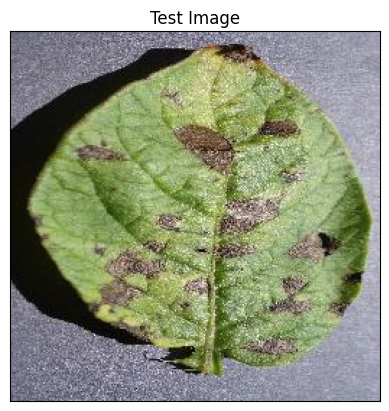

In [68]:
#Test Image Visualization
import cv2
image_path = '/content/plant_diseases/test/test/PotatoEarlyBlight2.JPG'
# Reading an image in default mode
img = cv2.imread(image_path)
img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB) #Converting BGR to RGB
# Displaying the image
plt.imshow(img)
plt.title('Test Image')
plt.xticks([])
plt.yticks([])
plt.show()

In [70]:
image = tf.keras.preprocessing.image.load_img(image_path,target_size=(224,224))
input_arr = tf.keras.preprocessing.image.img_to_array(image)
input_arr = np.array([input_arr])  # Convert single image to a batch.
predictions = cnn.predict(input_arr)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [71]:
print(predictions)

[[1.7243223e-15 3.2261445e-22 1.0307097e-21 1.4191455e-24 2.9795073e-24
  5.9935051e-22 3.9563182e-28 1.4878018e-17 6.2836889e-19 5.5045936e-20
  3.1045070e-29 1.6012465e-24 6.2879416e-24 8.3346040e-20 3.6715801e-28
  8.9257824e-26 1.7550117e-18 8.6268769e-26 1.4654829e-19 6.1221838e-25
  1.0000000e+00 4.4098658e-16 2.2402928e-22 4.3819524e-28 3.0335532e-28
  2.8788997e-21 1.2059128e-15 1.5940724e-25 2.5365695e-23 1.3437689e-16
  2.1206314e-13 4.1987529e-23 7.8539165e-15 2.8617427e-28 1.2710958e-23
  2.3588852e-29 8.6445577e-28 9.4244316e-22]]


In [72]:
result_index = np.argmax(predictions) #Return index of max element
print(result_index)

20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


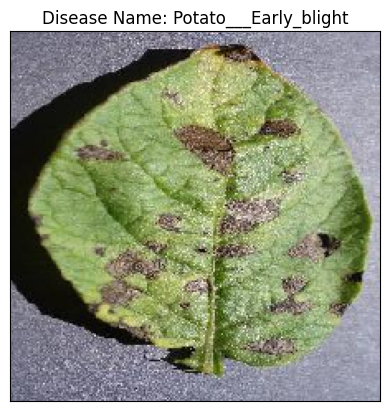

In [75]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Assuming 'cnn' is your trained model and 'img' is the image you want to classify

# Make a prediction for the image
img = tf.keras.preprocessing.image.load_img("/content/plant_diseases/test/test/PotatoEarlyBlight2.JPG", target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)  # Convert image to array
img_array = tf.expand_dims(img_array, 0)  # Add batch dimension

# Make a prediction
predictions = cnn.predict(img_array)
result_index = tf.argmax(predictions, axis=-1).numpy()[0]

# Ensure class_name is available from the validation set
class_name = validation_set.class_names

# Displaying the disease prediction
model_prediction = class_name[result_index]
plt.imshow(img)
plt.title(f"Disease Name: {model_prediction}")
plt.xticks([])  # Hide x-axis ticks
plt.yticks([])  # Hide y-axis ticks
plt.show()
